# Part 2 — Exploratory Data Analysis (EDA)

**Project:** Social Media and Stress Patterns
**Goal:** describe every variable and explore relationships with charts, so the modelling parts (3 & 4) know what to expect.

This notebook runs the full EDA pipeline from `scripts/eda.py` and shows all 17 charts inline.
Every chart is also saved as a PNG in `reports/figures/` for the final report.

Sections:
1. Overview (shape, types, summary stats)
2. Missing values (counts, per-row report, heatmap)
3. Univariate — distributions of all 7 numeric columns (histogram + boxplot + skewness)
4. Univariate — categorical counts (gender, platform, screen-time group)
5. Bivariate — scatter plots and group boxplots with correlation values
6. Correlation heatmap + top-5 strongest relationships
7. Outlier scan (IQR rule, report-only)

In [1]:
# Locate the project root (works whether this notebook runs from the
# project folder or from inside notebooks/).
from pathlib import Path

root = Path.cwd().resolve()
if not (root / "scripts" / "eda.py").exists():
    root = root.parent

script = root / "scripts" / "eda.py"
fig_dir = root / "reports" / "figures"
print("Project root:", root)

# Run the complete EDA pipeline (same code as scripts/eda.py).
# It prints every finding in plain English and saves 17 charts.
%run $script

Project root: /Users/jazmingill/social-media-stress-analysis


STARTING THE EDA
Loaded 500 rows x 11 columns from the cleaned file.

SECTION 1 - OVERVIEW
Rows: 500 | Columns: 11

Column types:
user_id                            str
age                              int64
gender                             str
daily_screen_time_hours        float64
sleep_quality                    int64
stress_level                     int64
days_without_social_media        int64
exercise_frequency_per_week      int64
social_media_platform              str
happiness_index                  int64
screen_time_group                  str

Numeric summary:
          age  daily_screen_time_hours  sleep_quality  stress_level  days_without_social_media  exercise_frequency_per_week  happiness_index
count  500.00                   500.00         500.00        500.00                     500.00                       500.00           500.00
mean    32.99                     5.53           6.30          6.62                       3.13                         2.45             8.38


    saved -> reports/figures/eda_stress_level.png
  stress_level: mean 6.62, median 7.00, skewness -0.09
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_days_without_social_media.png
  days_without_social_media: mean 3.13, median 3.00, skewness +0.08
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_exercise_frequency_per_week.png
  exercise_frequency_per_week: mean 2.45, median 2.00, skewness +0.24
      -> roughly symmetric or mildly skewed
    saved -> reports/figures/eda_happiness_index.png
  happiness_index: mean 8.38, median 9.00, skewness -0.69
      -> roughly symmetric or mildly skewed

SECTION 3b - UNIVARIATE (categorical columns)

  gender counts:
    Male: 248 (49.6%)
    Female: 229 (45.8%)
    Other: 23 (4.6%)
    saved -> reports/figures/eda_gender_counts.png

  social_media_platform counts:
    TikTok: 95 (19.0%)
    X (Twitter): 88 (17.6%)
    LinkedIn: 87 (17.4%)
    Facebook: 81 (16.2%)
    YouTube: 75 (15.0%)
 

    saved -> reports/figures/eda_screen_time_group_counts.png

SECTION 4 - BIVARIATE (relationships)
    saved -> reports/figures/eda_daily_screen_time_hours_vs_stress_level.png
  daily_screen_time_hours vs stress_level: correlation = +0.74
    saved -> reports/figures/eda_daily_screen_time_hours_vs_sleep_quality.png
  daily_screen_time_hours vs sleep_quality: correlation = -0.76
    saved -> reports/figures/eda_exercise_frequency_per_week_vs_happiness_index.png
  exercise_frequency_per_week vs happiness_index: correlation = +0.04
    saved -> reports/figures/eda_stress_level_by_screen_time_group.png

  Mean stress_level by screen_time_group:
    0-3 hrs: 4.38
    3-6 hrs: 6.0
    6-9 hrs: 7.63
    9-12 hrs: 9.15
    saved -> reports/figures/eda_sleep_quality_by_social_media_platform.png

  Mean sleep_quality by social_media_platform:
    Facebook: 6.1
    Instagram: 5.91
    LinkedIn: 6.55
    TikTok: 6.46
    X (Twitter): 6.39
    YouTube: 6.33
    saved -> reports/figures/eda_stress

    saved -> reports/figures/eda_correlation_heatmap.png

  Strongest relationships:
    daily_screen_time_hours <-> sleep_quality: -0.76 (negative)
    daily_screen_time_hours <-> stress_level: +0.74 (positive)
    stress_level <-> happiness_index: -0.74 (negative)
    daily_screen_time_hours <-> happiness_index: -0.71 (negative)
    sleep_quality <-> happiness_index: +0.68 (positive)

SECTION 6 - OUTLIER SCAN (IQR rule)
  age: 0 potential outlier(s) (outside -1.5 - 66.5)
  daily_screen_time_hours: 2 potential outlier(s) (outside 0.7 - 10.3)
  sleep_quality: 0 potential outlier(s) (outside 2.0 - 10.0)
  stress_level: 1 potential outlier(s) (outside 3.0 - 11.0)
  days_without_social_media: 0 potential outlier(s) (outside -2.5 - 9.5)
  exercise_frequency_per_week: 2 potential outlier(s) (outside -2.0 - 6.0)
  happiness_index: 0 potential outlier(s) (outside 2.5 - 14.5)

EDA FINISHED - all charts are in reports/figures/


17 EDA charts:

### eda_age.png


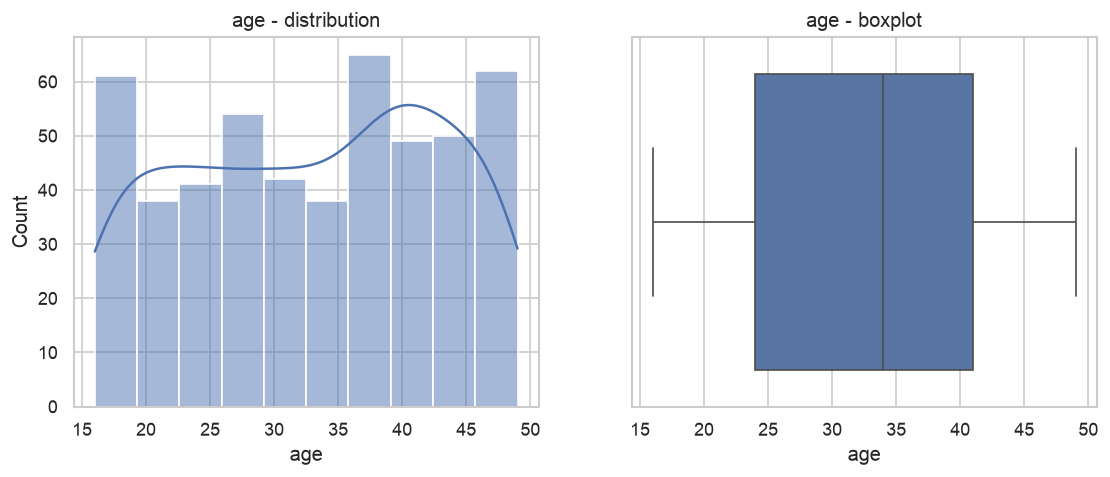


### eda_correlation_heatmap.png


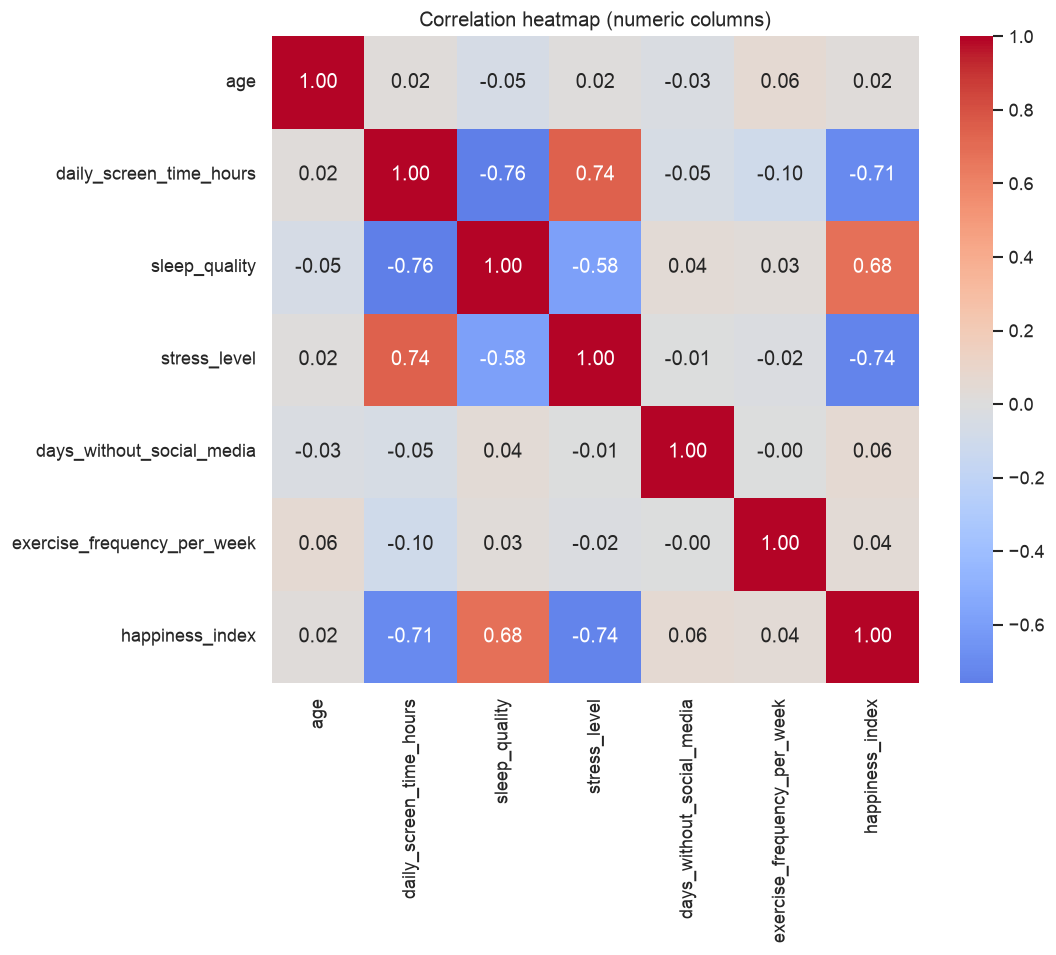


### eda_daily_screen_time_hours.png


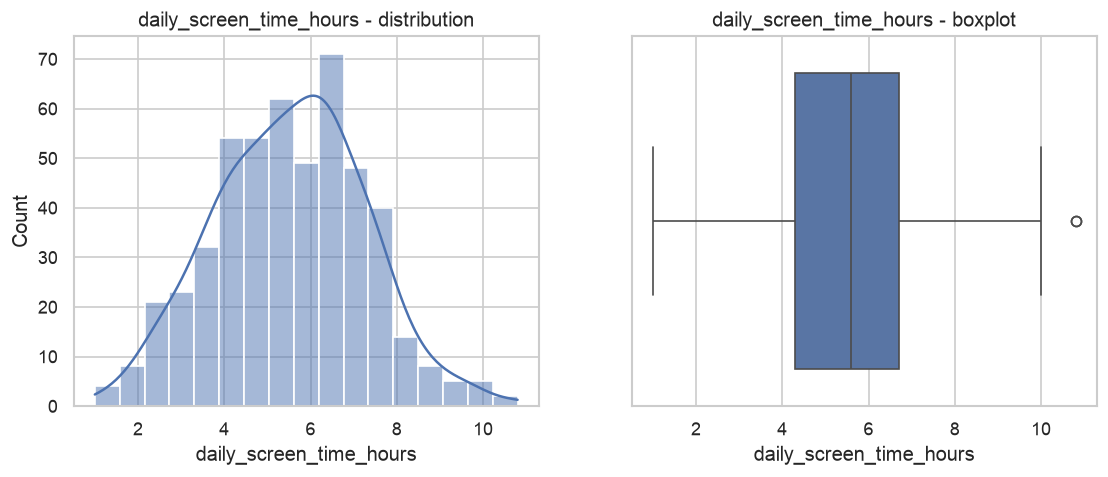


### eda_daily_screen_time_hours_vs_sleep_quality.png


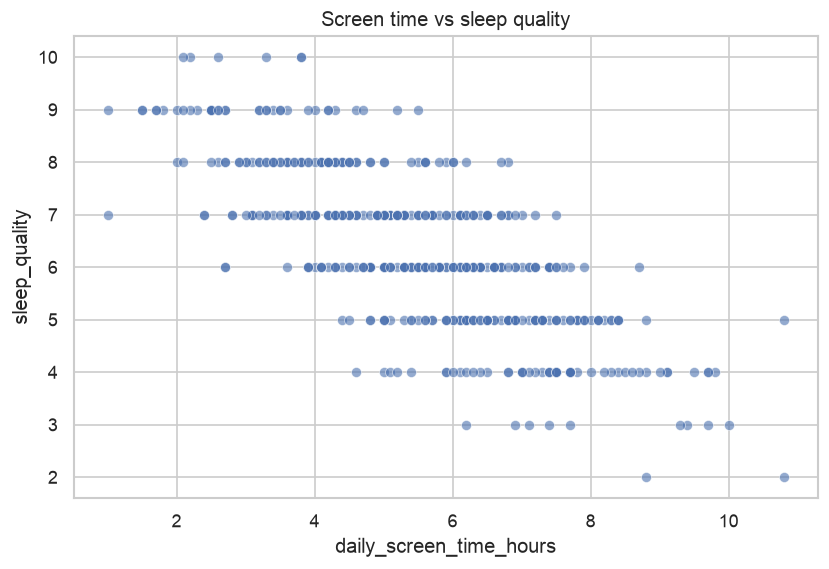


### eda_daily_screen_time_hours_vs_stress_level.png


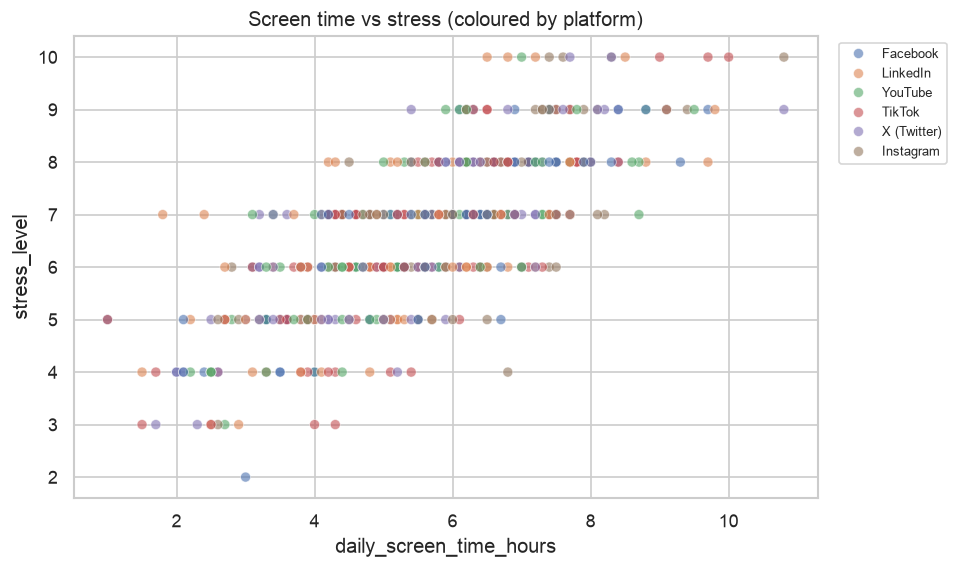


### eda_days_without_social_media.png


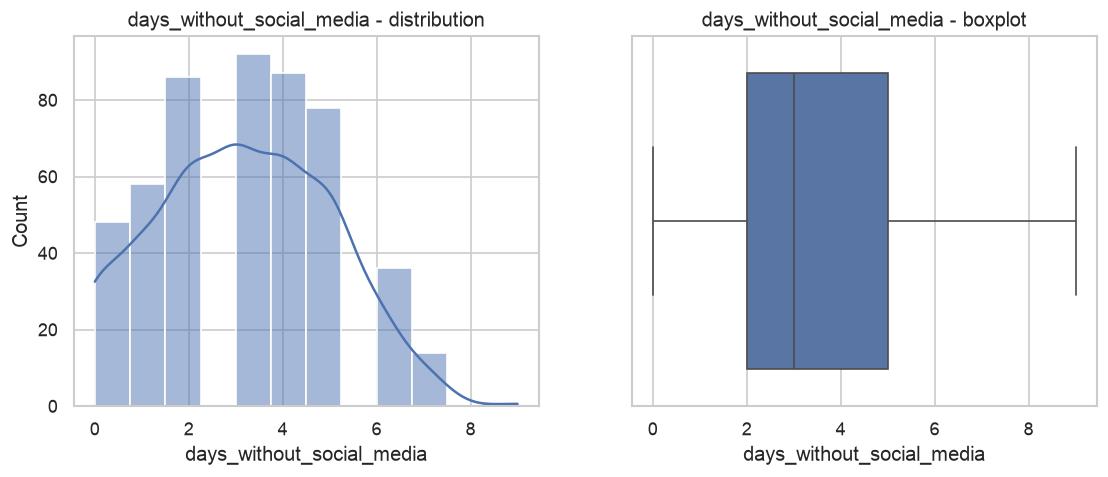


### eda_exercise_frequency_per_week.png


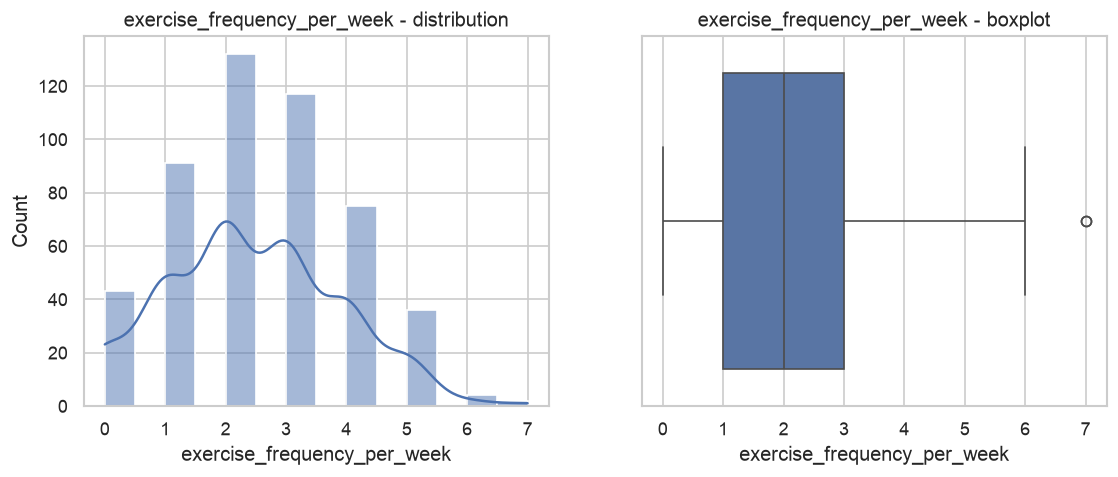


### eda_exercise_frequency_per_week_vs_happiness_index.png


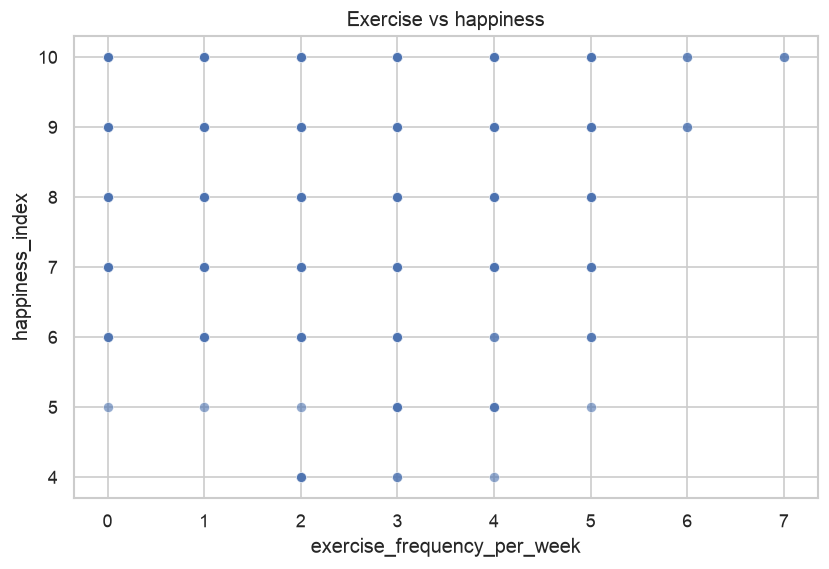


### eda_gender_counts.png


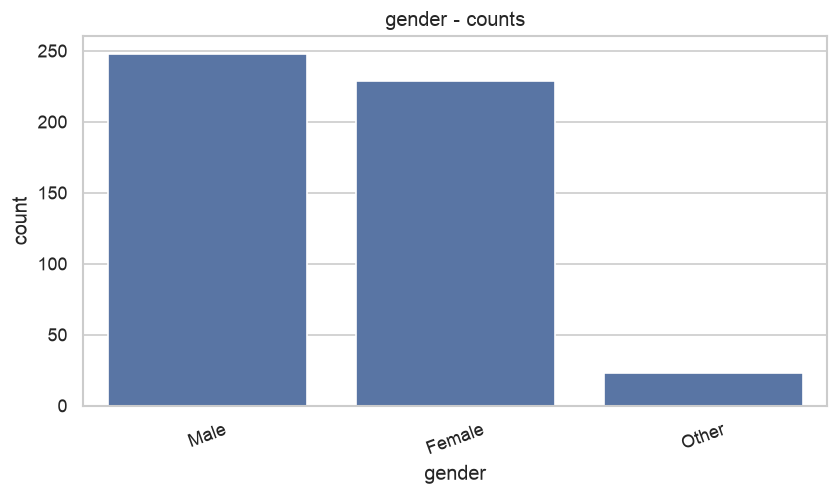


### eda_happiness_index.png


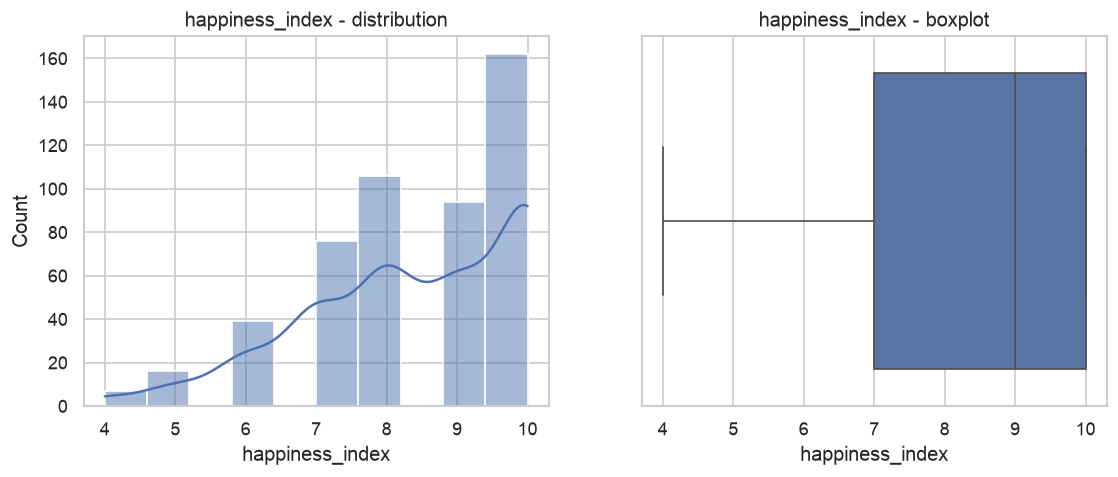


### eda_screen_time_group_counts.png


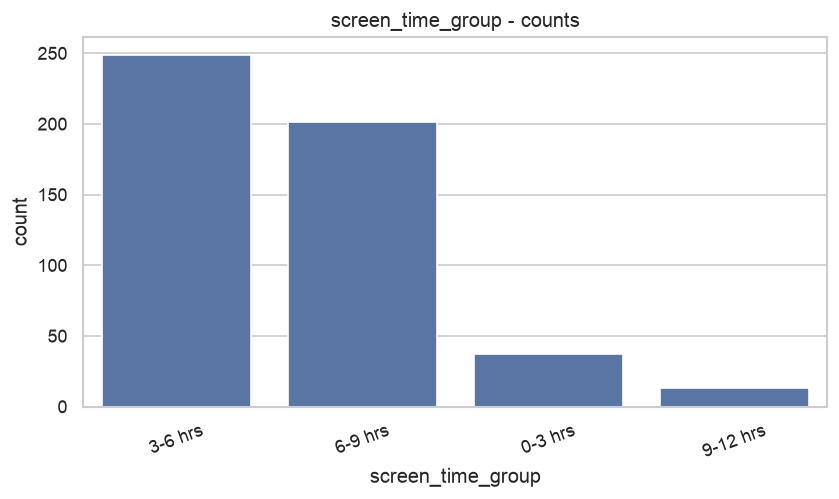


### eda_sleep_quality.png


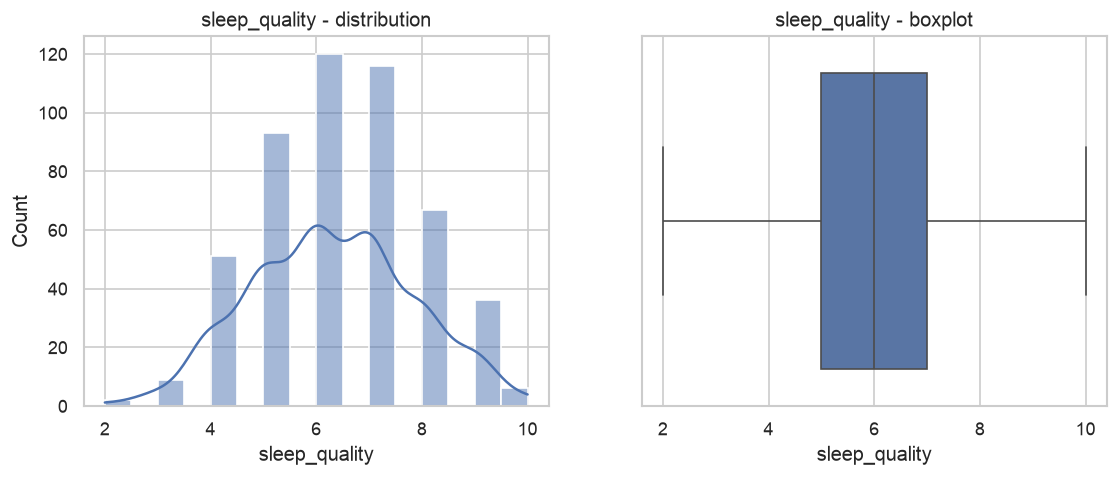


### eda_sleep_quality_by_social_media_platform.png


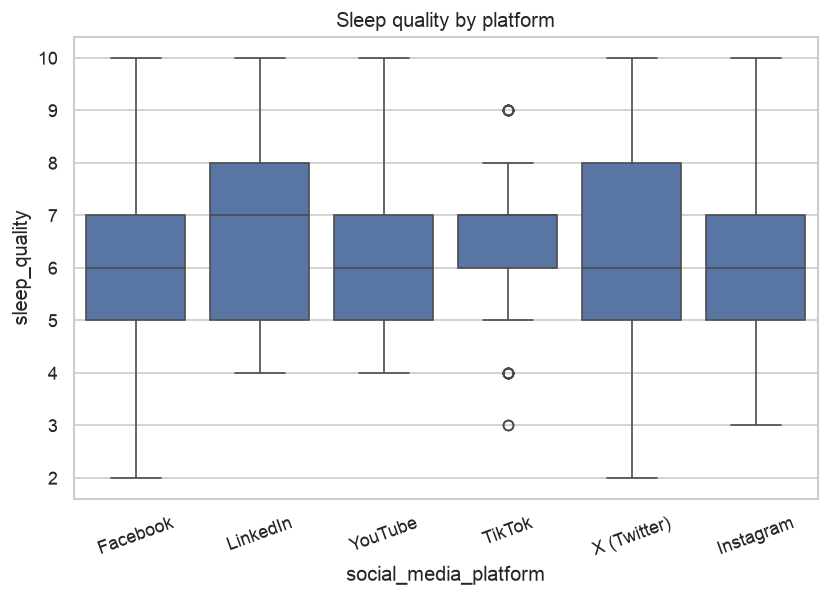


### eda_social_media_platform_counts.png


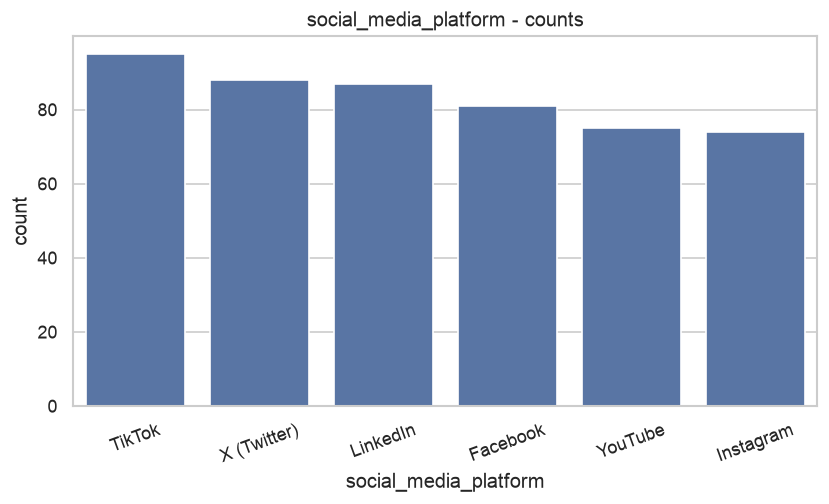


### eda_stress_level.png


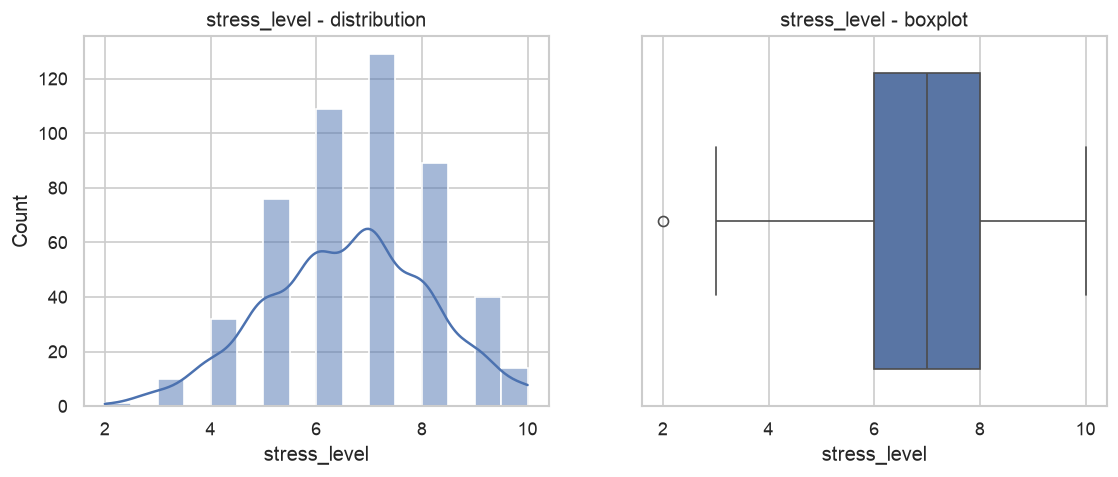


### eda_stress_level_by_gender.png


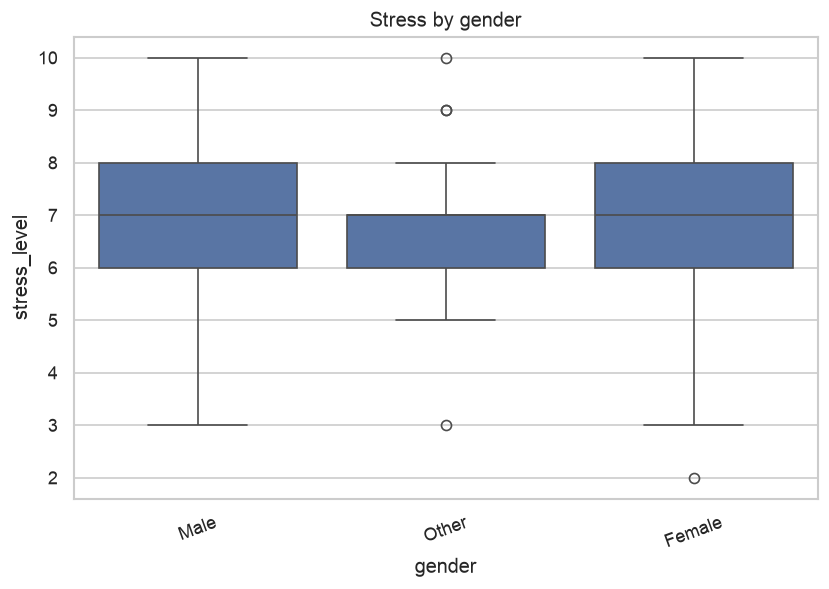


### eda_stress_level_by_screen_time_group.png


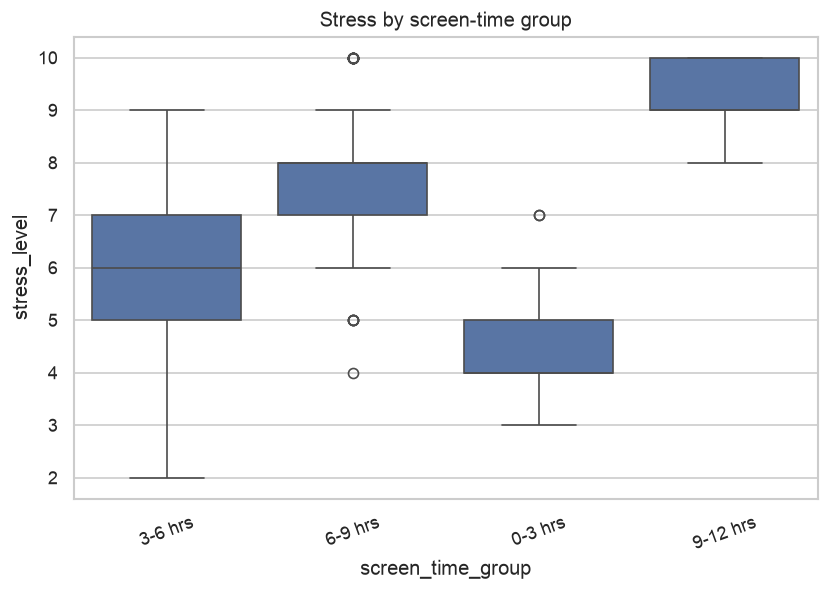

In [2]:
# Show every EDA chart inline so the whole analysis can be reviewed here.
from IPython.display import Image, display

figures = sorted(fig_dir.glob("eda_*.png"))
print(f"{len(figures)} EDA charts:")

for path in figures:
    print("\n###", path.name)
    display(Image(filename=str(path)))